In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#PART 1

In [9]:
crm = pd.read_csv("CRM.csv")
crm["ticker"] = "CRM"
lmt = pd.read_csv("LMT.csv")
lmt["ticker"] = "LMT"
rol = pd.read_csv("ROL.csv")
rol["ticker"] = "ROL"
rtx = pd.read_csv("RTX.csv")
rtx["ticker"] = "RTX"
wab = pd.read_csv("WAB.csv")
wab["ticker"] = "WAB"

df = pd.concat([crm, lmt, rol, rtx, wab])
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,ticker
0,2022-01-03,250.233,251.891,243.992,250.675,4316800,0.0,0.0,CRM
1,2022-01-04,252.039,252.058,238.840,243.580,7240700,0.0,0.0,CRM
2,2022-01-05,231.746,233.738,223.052,223.405,18882500,0.0,0.0,CRM
3,2022-01-06,223.768,230.088,221.816,224.857,9376100,0.0,0.0,CRM
4,2022-01-07,224.220,227.929,221.815,224.033,6286700,0.0,0.0,CRM


In [14]:
#Ex 1
df["dif"] = df["High"] - df["Low"]

dif = df.groupby("ticker")["dif"].sum()
print(dif)

for ticker, value in dif.items():
    if ticker == 0:
        print("The company", ticker, "has no difference between Hiogh and Low")

ticker
CRM    5963.337
LMT    7678.547
ROL     792.528
RTX    1939.478
WAB    2758.656
Name: dif, dtype: float64


In [27]:
#Ex 2
stat = {
    "Highest_price": df.groupby("ticker")["High"].max(),
    "Lowest_price": df.groupby("ticker")["Low"].min()
}

stat = pd.DataFrame(stat)
print(stat)

        Highest_price  Lowest_price
ticker                             
CRM           363.695       123.973
LMT           586.852       311.388
ROL            60.830        26.642
RTX           185.983        64.579
WAB           221.702        76.478


In [28]:
#Ex 3
df["log_return"] = np.log(df["Close"]) - np.log(df["Close"].shift(1))

df.groupby("ticker")["log_return"].agg(["min", "max", "mean", "std", "skew"])

,min,max,mean,std,skew
ticker,,,,,
CRM,-0.219861,0.108829,0.000052,0.023372,-0.613592
LMT,-0.114417,0.168438,0.000595,0.015134,0.742011
ROL,-2.725592,0.095726,-0.002083,0.087450,-30.235849
RTX,-0.107758,0.279010,0.001117,0.017523,3.512910
WAB,-0.705657,0.095630,0.000170,0.027718,-16.507345


In [38]:
#Ex 4 ###
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index(df["Date"])

stat2 = {
    "Highest_return_date": df.groupby("ticker")["log_return"].idxmax(),
    "Lowest_return_date": df.groupby("ticker")["log_return"].idxmin()
}

stat2 = pd.DataFrame(stat2)
print(stat2)


       Highest_return_date Lowest_return_date
ticker                                       
CRM             2023-03-02         2024-05-30
LMT             2022-01-03         2025-07-22
ROL             2022-10-26         2022-01-03
RTX             2022-01-03         2023-07-25
WAB             2024-04-24         2022-01-03


In [41]:
#Ex 5
week = df.groupby("ticker")["Volume"].resample("W").sum()
print(week)

week.groupby("ticker").sum()

ticker  Date      
CRM     2022-01-09    46102800
        2022-01-16    34643400
        2022-01-23    26156700
        2022-01-30    48503600
        2022-02-06    41853300
                        ...   
WAB     2025-12-07     3789000
        2025-12-14     3375100
        2025-12-21     6299300
        2025-12-28     2228000
        2026-01-04     1027200
Name: Volume, Length: 1045, dtype: int64


ticker
CRM    7086326900
LMT    1377984400
ROL    1815563600
RTX    5862737800
WAB    1000649100
Name: Volume, dtype: int64

In [50]:
#Ex 6
total_return = df.groupby("ticker")["log_return"].sum()

print(total_return)

result = total_return.idxmin()
result2 = total_return.min()
print("The company", result, "recorded the lowest total retunr", result2)

ticker
CRM    0.052205
LMT    0.596007
ROL   -2.087351
RTX    1.119181
WAB    0.170811
Name: log_return, dtype: float64
The company ROL recorded the lowest total retunr -2.0873505626151765


In [53]:
#Ex 7 ###
df
#df["volume_class"] 

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,ticker,dif,lof_return,log_return
Date,,,,,,,,,,,,
2022-01-03,2022-01-03,250.233,251.891,243.992,250.675,4316800,0.0,0.0,CRM,7.899,NaN,NaN
2022-01-04,2022-01-04,252.039,252.058,238.840,243.580,7240700,0.0,0.0,CRM,13.218,-0.028712,-0.028712
2022-01-05,2022-01-05,231.746,233.738,223.052,223.405,18882500,0.0,0.0,CRM,10.686,-0.086459,-0.086459
2022-01-06,2022-01-06,223.768,230.088,221.816,224.857,9376100,0.0,0.0,CRM,8.272,0.006478,0.006478
2022-01-07,2022-01-07,224.220,227.929,221.815,224.033,6286700,0.0,0.0,CRM,6.114,-0.003671,-0.003671
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-23,2025-12-23,219.878,221.124,218.094,218.792,750500,0.0,0.0,WAB,3.030,-0.009792,-0.009792
2025-12-24,2025-12-24,218.991,220.526,218.284,219.001,234900,0.0,0.0,WAB,2.242,0.000955,0.000955
2025-12-26,2025-12-26,218.682,219.579,217.447,218.553,244400,0.0,0.0,WAB,2.132,-0.002048,-0.002048


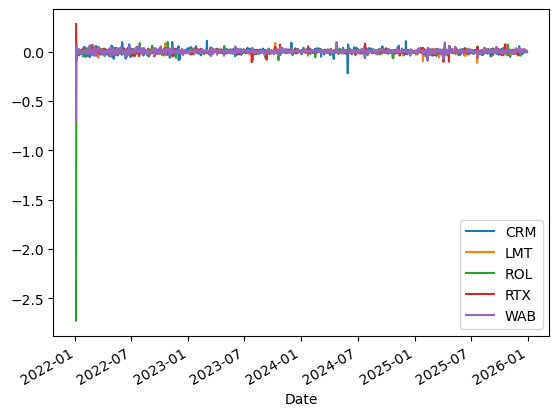

In [65]:
#Ex 8 
#(A)
log_ret_comp = df.groupby("ticker")["log_return"]

fig, ax = plt.subplots()
log_ret_comp.plot()
plt.legend()
plt.show()

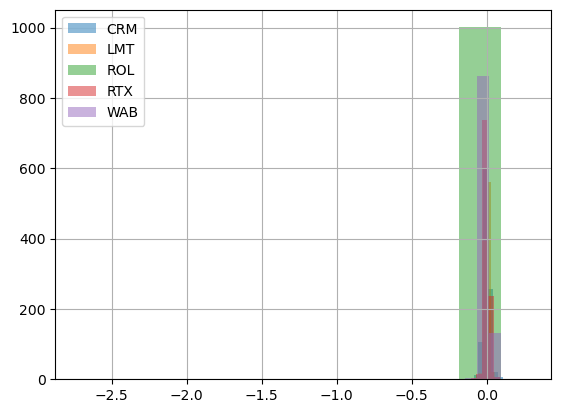

In [69]:
#(B)
fig, ax = plt.subplots()
log_ret_comp.hist(alpha = 0.5, legend = True)
plt.legend()
plt.show()

In [70]:
#PART 2 

In [2]:
#Ex 1
df = pd.read_csv("companies_no_subindustry.csv")
print(df.head())
len(df)

df["included"].isna().sum()

  Symbol     Security  GICS_Sector                       hq    included  \
0    MMM           3M  Industrials    Saint Paul, Minnesota  09.08.1976   
1    AOS  A. O. Smith  Industrials     Milwaukee, Wisconsin  26.07.2017   
2    ABT       Abbott  Health Care  North Chicago, Illinois  31.03.1964   
3   ABBV       AbbVie  Health Care  North Chicago, Illinois  31.12.2012   
4   ABMD      Abiomed  Health Care   Danvers, Massachusetts  31.05.2018   

       Founded  
0         1902  
1         1916  
2         1888  
3  2013 (1888)  
4         1981  


np.int64(45)

In [7]:
#Ex 2 ####
df = df.dropna(subset = ["included"])
len(df)

df["included"] = pd.to_datetime(df["included"], dayfirst = True, errors = "coerce")
df = df.set_index(df["included"])
#df["Founded"] = pd.to_numeric(df["Founded"], errors = "coerce")

old = df.loc[df["included"].min()]
young = df.loc[df["included"].max()]
old
#old_old = old.loc[df["Founded"].min()]
#old_old
#print("The oldest company is", old["Symbol"], "included on", old["included"], "and founded on", old["Founded"])
#print("The youndest company is", old["Symbol"], "included on", young["included"], "and founded on", young["Founded"])

,Symbol,Security,GICS_Sector,hq,included,Founded
included,,,,,,
1957-03-04,MO,Altria,Consumer Staples,"Richmond, Virginia",1957-03-04,1985
1957-03-04,AEP,American Electric Power,Utilities,"Columbus, Ohio",1957-03-04,1906
1957-03-04,BA,Boeing,Industrials,"Chicago, Illinois",1957-03-04,1916
1957-03-04,BMY,Bristol Myers Squibb,Health Care,"New York City, New York",1957-03-04,1989
1957-03-04,CPB,Campbell Soup Company,Consumer Staples,"Camden, New Jersey",1957-03-04,1869
1957-03-04,CAT,Caterpillar Inc.,Industrials,"Irving, Texas",1957-03-04,1925
1957-03-04,CVX,Chevron Corporation,Energy,"San Ramon, California",1957-03-04,1879
1957-03-04,KO,The Coca-Cola Company,Consumer Staples,"Atlanta, Georgia",1957-03-04,1886
1957-03-04,CL,Colgate-Palmolive,Consumer Staples,"New York City, New York",1957-03-04,1806


GICS_Sector
Information Technology    68
Industrials               66
Health Care               60
Financials                55
Consumer Discretionary    52
Consumer Staples          33
Real Estate               29
Materials                 26
Communication Services    22
Utilities                 22
Energy                    22
Name: count, dtype: int64


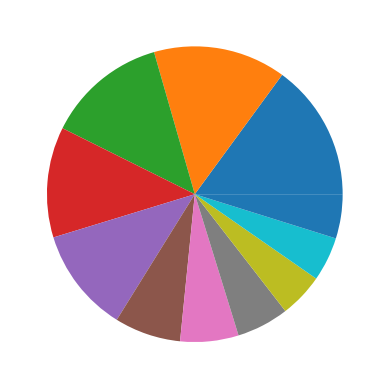

In [22]:
#Ex 3 ###
GISC = df["GICS_Sector"].value_counts()
print(GISC)

fix, ax = plt.subplots()
ax.pie(GISC)
plt.show()

state
 California                    65
 New York                      43
 Texas                         40
 Illinois                      31
 Pennsylvania                  19
 Massachusetts                 18
 Ohio                          17
 North Carolina                16
 Georgia                       16
 New Jersey                    15
 Virginia                      15
 Florida                       14
 Minnesota                     13
 Washington                    12
 Connecticut                   12
 Michigan                      10
 Ireland                        7
 Colorado                       7
 Tennessee                      7
 Missouri                       6
 Wisconsin                      6
 Indiana                        6
 Arizona                        5
 Maryland                       5
 United Kingdom                 4
 Rhode Island                   4
 Nevada                         4
 Oklahoma                       4
 Louisiana                      3
 Arkansa

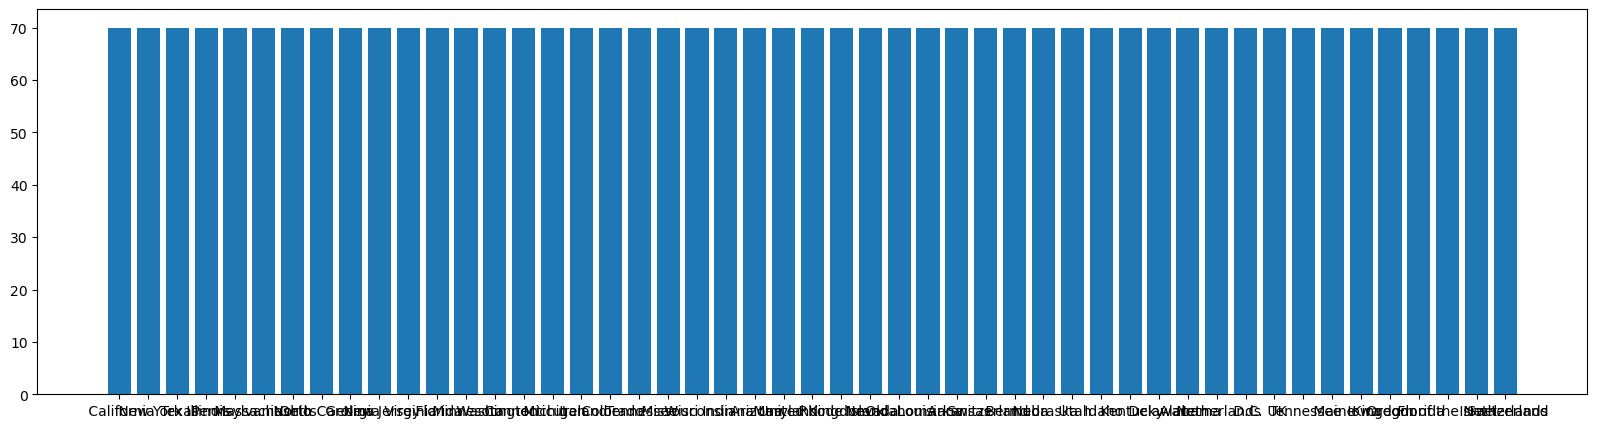

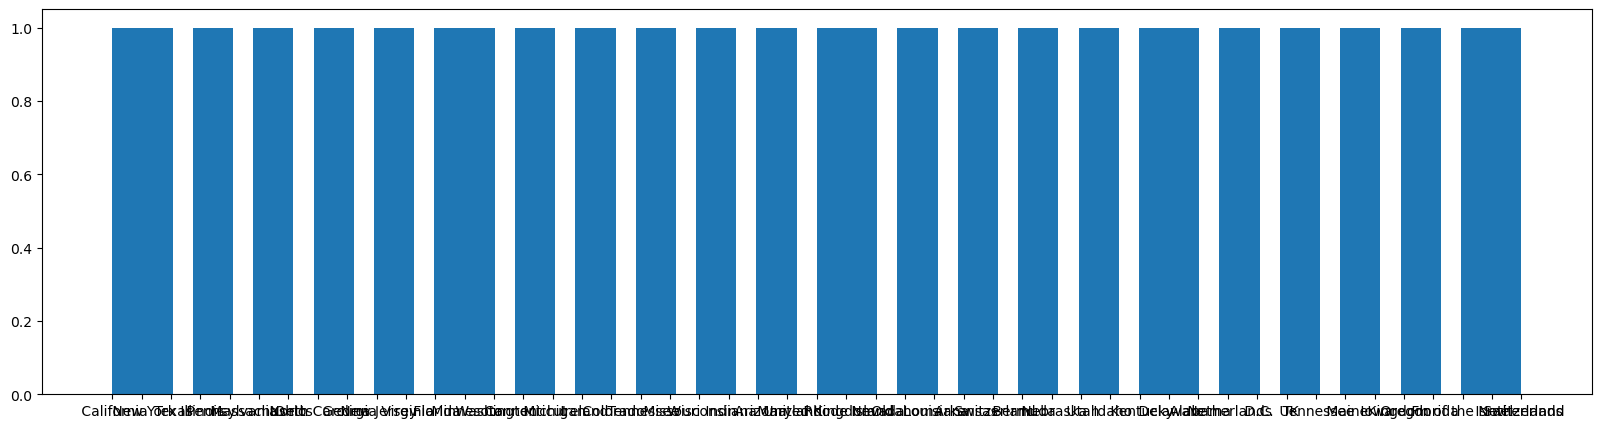

In [57]:
#Ex 4 
df["state"] = df["hq"].apply(lambda x: x.split(",")[-1])
bar = df["state"].value_counts()
print(bar)

fix, ax = plt.subplots(figsize = (20,5))
ax.bar(bar.index, 70)
plt.show()

fix, ax = plt.subplots(figsize = (20,5))
ax.hist(bar.index, 70)
plt.show()

GICS_Sector  subindustry                   
Health Care  Health Care Equipment             18
             Pharmaceuticals                    9
             Biotechnology                      7
             Life Sciences Tools & Services     7
             Managed Health Care                5
             Health Care Distributors           4
             Health Care Supplies               4
             Health Care Facilities             3
             Health Care Services               3
Name: count, dtype: int64


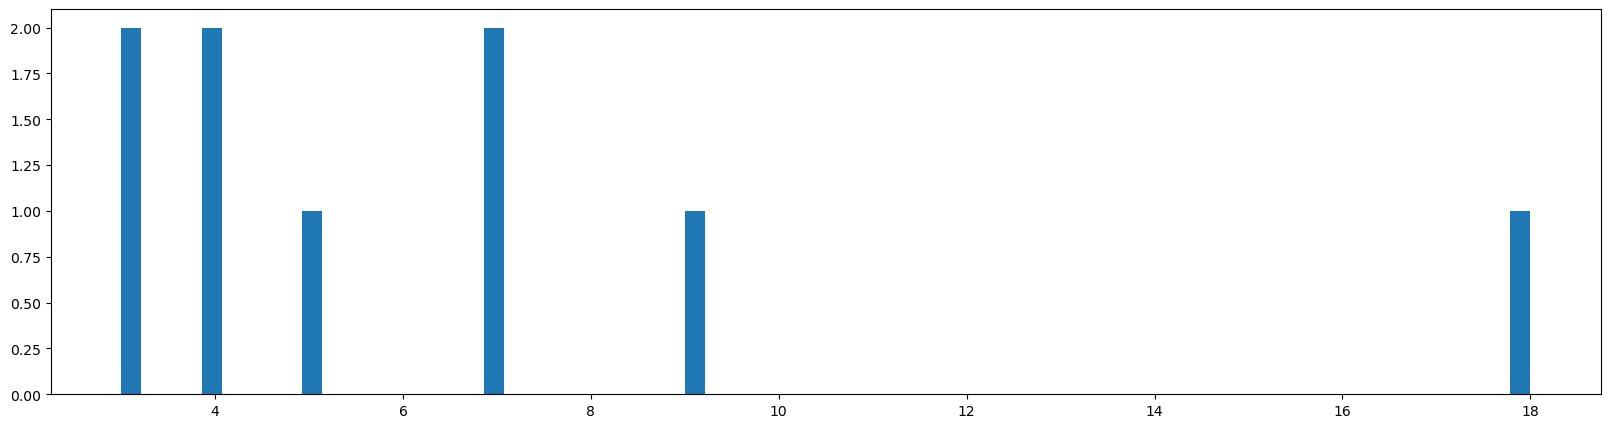

In [56]:
#Ex 5
df2 = pd.read_csv("companies_subindustry.csv")
df2
data = df.merge(df2, on = "Symbol") 
data.head()
dist = data[data["GICS_Sector"] == "Health Care"].groupby("GICS_Sector")["subindustry"].value_counts()
print(dist)

fix, ax = plt.subplots(figsize = (20,5))
ax.hist(dist,  70)
plt.show()